# EN4554 Assignment 2 : CNNs

**Name:** Indunil W.A.K.  
**Index:** 220240G  
**GitHub:** https://github.com/indunil-k/CNNs_220240G.git  

Test data is reserved for Task 4.

## 0. Setup

We fix seeds, create a fixed 45,000/5,000 split, and compute normalization statistics from the training subset only.

In [3]:
import random
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import transforms

SEED = 42
NUM_WORKERS = 0  # reliable on both laptops and Colab
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Device:', device)

COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False,
                     'axes.spines.right': False, 'lines.linewidth': 2, 'figure.dpi': 110})

PyTorch: 2.14.1+cpu
Device: cpu


In [4]:
raw_transform = transforms.ToTensor()
raw_train = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=raw_transform)
generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(len(raw_train), generator=generator).tolist()
train_indices = permutation[:45000]
val_indices = permutation[45000:]

stats_loader = DataLoader(Subset(raw_train, train_indices), batch_size=512, shuffle=False, num_workers=NUM_WORKERS)
channel_sum = torch.zeros(3)
channel_squared_sum = torch.zeros(3)
pixel_count = 0
for images, _ in stats_loader:
    images = images.float()
    channel_sum += images.sum(dim=(0, 2, 3))
    channel_squared_sum += (images ** 2).sum(dim=(0, 2, 3))
    pixel_count += images.shape[0] * images.shape[2] * images.shape[3]
mean = channel_sum / pixel_count
std = torch.sqrt(channel_squared_sum / pixel_count - mean ** 2)
print('Training mean:', mean)
print('Training std:', std)
print('Train size:', len(train_indices), 'Validation size:', len(val_indices))

Training mean: tensor([0.4917, 0.4823, 0.4467])
Training std: tensor([0.2471, 0.2435, 0.2616])
Train size: 45000 Validation size: 5000


In [5]:
normalize = transforms.Normalize(mean=mean.tolist(), std=std.tolist())
transform = transforms.Compose([transforms.ToTensor(), normalize])
train_dataset_full = torchvision.datasets.CIFAR10(root='./data', train=True, download=False, transform=transform)
train_dataset = Subset(train_dataset_full, train_indices)
val_dataset = Subset(train_dataset_full, val_indices)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
print('Setup complete. Test data remains unused until Task 4.')

Setup complete. Test data remains unused until Task 4.


### Setup interpretation

The split is fixed by the seed, so all experiments can be compared fairly. Normalization uses only training statistics, preventing validation or test information from entering preprocessing.

## Task 1: Backpropagation

Every layer is a small module with two methods:

- `forward(x)`: compute the output and **cache** whatever backward will need.
- `backward(grad_out)`: receive $\partial L/\partial \text{output}$, store the parameter gradients, and return $\partial L/\partial \text{input}$.

Backpropagation is the chain rule applied layer by layer in reverse order. No autograd is used in these layers.

### 1(a) Linear, ReLU, softmax cross-entropy and the MLP

For a batch of $N$ samples, $x \in \mathbb{R}^{N\times D}$, $W \in \mathbb{R}^{D\times M}$ and upstream gradient $G = \partial L/\partial y \in \mathbb{R}^{N\times M}$:

| Layer | Forward | Backward |
|---|---|---|
| Linear | $y = xW + b$ | $\frac{\partial L}{\partial W} = x^\top G,\;\; \frac{\partial L}{\partial b} = \sum_n G_n,\;\; \frac{\partial L}{\partial x} = G W^\top$ |
| ReLU | $y = \max(0, x)$ | $\frac{\partial L}{\partial x} = G \odot \mathbb{1}[x > 0]$ |
| Sigmoid (for 1(d)) | $y = \sigma(x)$ | $\frac{\partial L}{\partial x} = G \odot y(1-y)$ |
| Softmax + CE | $p = \mathrm{softmax}(z),\; L = -\frac{1}{N}\sum_n \log p_{n,y_n}$ | $\frac{\partial L}{\partial z} = \frac{1}{N}(p - \mathrm{onehot}(y))$ |

Weights use Kaiming (He) initialization, $W \sim \mathcal{N}(0, 2/D)$.

In [6]:
class Linear:
    def __init__(self, in_features, out_features, dtype=torch.float32, device='cpu'):
        self.W = torch.randn(in_features, out_features, dtype=dtype, device=device) * (2.0 / in_features) ** 0.5
        self.b = torch.zeros(out_features, dtype=dtype, device=device)

    def forward(self, x):
        self.x = x                          # cached for backward
        return x @ self.W + self.b

    def backward(self, grad_out):
        self.dW = self.x.T @ grad_out       # (D,N) @ (N,M) -> (D,M)
        self.db = grad_out.sum(dim=0)       # b is added to every sample, so sum over the batch
        return grad_out @ self.W.T          # (N,M) @ (M,D) -> (N,D)

    def parameters(self):
        return [self.W, self.b]

    def gradients(self):
        return [self.dW, self.db]


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, grad_out):
        return grad_out * self.mask         # gradient passes only where the unit was active


class Sigmoid:
    def forward(self, x):
        self.out = 1.0 / (1.0 + torch.exp(-x))
        return self.out

    def backward(self, grad_out):
        return grad_out * self.out * (1.0 - self.out)   # sigma'(x) = sigma(x)(1 - sigma(x)) <= 0.25


class SoftmaxCrossEntropy:
    def forward(self, logits, labels):
        shifted = logits - logits.max(dim=1, keepdim=True).values      # avoids exp overflow; softmax is unchanged
        log_probs = shifted - torch.log(torch.exp(shifted).sum(dim=1, keepdim=True))
        self.probs = torch.exp(log_probs)
        self.labels = labels
        return -log_probs[torch.arange(len(labels)), labels].mean()

    def backward(self):
        n = len(self.labels)
        grad = self.probs.clone()
        grad[torch.arange(n), self.labels] -= 1.0                      # p - onehot(y)
        return grad / n                                                 # the loss is a mean over the batch


class MLP:
    def __init__(self, sizes, activation=ReLU, dtype=torch.float32, device='cpu'):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], dtype, device))
            if i < len(sizes) - 2:                                      # no activation on the output logits
                self.layers.append(activation())
        self.criterion = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, labels):
        return self.criterion.forward(self.forward(x), labels)

    def backward(self):
        grad = self.criterion.backward()
        for layer in reversed(self.layers):
            grad = layer.backward(grad)

    def linear_layers(self):
        return [layer for layer in self.layers if isinstance(layer, Linear)]

    def parameters(self):
        return [p for layer in self.linear_layers() for p in layer.parameters()]

    def gradients(self):
        return [g for layer in self.linear_layers() for g in layer.gradients()]

### 1(b) Gradient check

The manual gradients are compared with two independent references:

- **Autograd:** the same network rebuilt from PyTorch ops (`torch.relu`, `F.cross_entropy`) and differentiated by `loss.backward()`.
- **Centred finite differences:** $\frac{\partial L}{\partial \theta_i} \approx \frac{L(\theta_i + h) - L(\theta_i - h)}{2h}$, whose truncation error is $O(h^2)$ (a one-sided difference is only $O(h)$).

The check runs in float64 with $h = 10^{-6}$, so rounding error ($\approx \epsilon/h$) stays far below any real bug. Relative error is $\lVert g_\text{manual} - g_\text{ref}\rVert \,/\, \max(\lVert g_\text{manual}\rVert, \lVert g_\text{ref}\rVert)$.

In [7]:
def autograd_gradients(model, x, labels):
    params = [p.clone().requires_grad_(True) for p in model.parameters()]
    h = x
    num_linear = len(params) // 2
    for i in range(num_linear):
        h = h @ params[2 * i] + params[2 * i + 1]
        if i < num_linear - 1:
            h = torch.relu(h)
    F.cross_entropy(h, labels).backward()
    return [p.grad for p in params]


def finite_difference_gradients(model, x, labels, h=1e-6):
    grads = []
    for param in model.parameters():
        grad = torch.zeros_like(param)
        flat_param, flat_grad = param.view(-1), grad.view(-1)
        for i in range(flat_param.numel()):
            original = flat_param[i].item()
            flat_param[i] = original + h
            loss_plus = model.loss(x, labels).item()
            flat_param[i] = original - h
            loss_minus = model.loss(x, labels).item()
            flat_param[i] = original                                    # restore the weight
            flat_grad[i] = (loss_plus - loss_minus) / (2 * h)
        grads.append(grad)
    return grads


def relative_error(a, b):
    return ((a - b).norm() / torch.maximum(a.norm(), b.norm()).clamp_min(1e-12)).item()


torch.manual_seed(SEED)
check_model = MLP([20, 16, 16, 10], dtype=torch.float64)
x_check = torch.randn(8, 20, dtype=torch.float64)
y_check = torch.randint(0, 10, (8,))

check_model.loss(x_check, y_check)
check_model.backward()
manual = check_model.gradients()               # computed before finite differences overwrite the caches
auto = autograd_gradients(check_model, x_check, y_check)
numeric = finite_difference_gradients(check_model, x_check, y_check)

names = [f'{kind}{i + 1}' for i in range(len(check_model.linear_layers())) for kind in ('W', 'b')]
print(f"{'param':<7}{'shape':<10}{'rel. err vs autograd':>22}{'allclose':>10}{'rel. err vs finite diff':>25}{'allclose':>10}")
for name, m, a, n in zip(names, manual, auto, numeric):
    print(f'{name:<7}{str(tuple(m.shape)):<10}{relative_error(m, a):>22.2e}{str(torch.allclose(m, a)):>10}'
          f'{relative_error(m, n):>25.2e}{str(torch.allclose(m, n)):>10}')

param  shape       rel. err vs autograd  allclose  rel. err vs finite diff  allclose
W1     (20, 16)                9.77e-17      True                 1.63e-09      True
b1     (16,)                   8.93e-17      True                 1.41e-09      True
W2     (16, 16)                6.19e-17      True                 1.54e-09      True
b2     (16,)                   9.01e-17      True                 1.79e-09      True
W3     (16, 10)                5.33e-17      True                 1.20e-09      True
b3     (10,)                   8.83e-17      True                 1.22e-09      True


**Interpretation.** All six parameter tensors pass `torch.allclose` against both references.

- **Against autograd** the relative error is about $10^{-16}$, which is float64 machine precision. Both methods compute the same algebra and differ only in the order of floating-point operations.
- **Against finite differences** it is about $10^{-9}$, as expected from an approximation. Its rounding error is about $\epsilon/h \approx 10^{-16}/10^{-6} = 10^{-10}$, and the $O(h^2) \approx 10^{-12}$ truncation error is smaller still.

A real bug, such as forgetting the $1/N$ in the softmax gradient, would give a relative error of order 1. So the manual backward passes are correct.

### 1(c) Training the MLP with SGD

Each image is flattened to a 3072-vector ($32\times32\times3$). The network is 3072 → 512 → 256 → 10 with ReLU, trained with plain mini-batch SGD, $\theta \leftarrow \theta - \eta \nabla_\theta L$, with batch size 128, $\eta = 0.05$ and 20 epochs.

In [8]:
def evaluate_mlp(model, loader):
    total_loss, correct, count = 0.0, 0, 0
    for images, labels in loader:
        x, labels = images.view(len(images), -1).to(device), labels.to(device)
        logits = model.forward(x)
        total_loss += model.criterion.forward(logits, labels).item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        count += len(labels)
    return total_loss / count, correct / count


torch.manual_seed(SEED)
mlp = MLP([3072, 512, 256, 10], device=device)
lr, epochs = 0.05, 20
history = {'iter_loss': [], 'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(epochs):
    loss_sum, correct, seen = 0.0, 0, 0
    for images, labels in train_loader:
        x, labels = images.view(len(images), -1).to(device), labels.to(device)
        logits = mlp.forward(x)
        loss = mlp.criterion.forward(logits, labels)
        mlp.backward()
        for param, grad in zip(mlp.parameters(), mlp.gradients()):
            param -= lr * grad                                          # SGD step
        history['iter_loss'].append(loss.item())
        loss_sum += loss.item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        seen += len(labels)
    val_loss, val_acc = evaluate_mlp(mlp, val_loader)
    history['train_loss'].append(loss_sum / seen)
    history['train_acc'].append(correct / seen)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    print(f'epoch {epoch + 1:2d} | train loss {loss_sum / seen:.3f} acc {correct / seen:.2%} '
          f'| val loss {val_loss:.3f} acc {val_acc:.2%}')

print(f"\nFinal validation accuracy: {history['val_acc'][-1]:.2%} (best {max(history['val_acc']):.2%})")

epoch  1 | train loss 1.699 acc 40.54% | val loss 1.554 acc 45.38%
epoch  2 | train loss 1.419 acc 50.29% | val loss 1.479 acc 47.22%
epoch  3 | train loss 1.289 acc 55.09% | val loss 1.488 acc 47.60%
epoch  4 | train loss 1.192 acc 58.67% | val loss 1.570 acc 46.94%
epoch  5 | train loss 1.108 acc 61.60% | val loss 1.485 acc 48.60%
epoch  6 | train loss 1.018 acc 65.10% | val loss 1.439 acc 51.20%
epoch  7 | train loss 0.945 acc 67.70% | val loss 1.467 acc 50.44%
epoch  8 | train loss 0.868 acc 70.28% | val loss 1.609 acc 47.58%
epoch  9 | train loss 0.805 acc 72.52% | val loss 1.620 acc 49.02%
epoch 10 | train loss 0.740 acc 74.85% | val loss 1.618 acc 49.76%
epoch 11 | train loss 0.680 acc 77.08% | val loss 1.655 acc 50.00%
epoch 12 | train loss 0.620 acc 78.89% | val loss 1.632 acc 50.04%
epoch 13 | train loss 0.556 acc 81.38% | val loss 1.729 acc 50.36%
epoch 14 | train loss 0.509 acc 83.26% | val loss 1.931 acc 48.20%
epoch 15 | train loss 0.457 acc 84.92% | val loss 1.894 acc 48

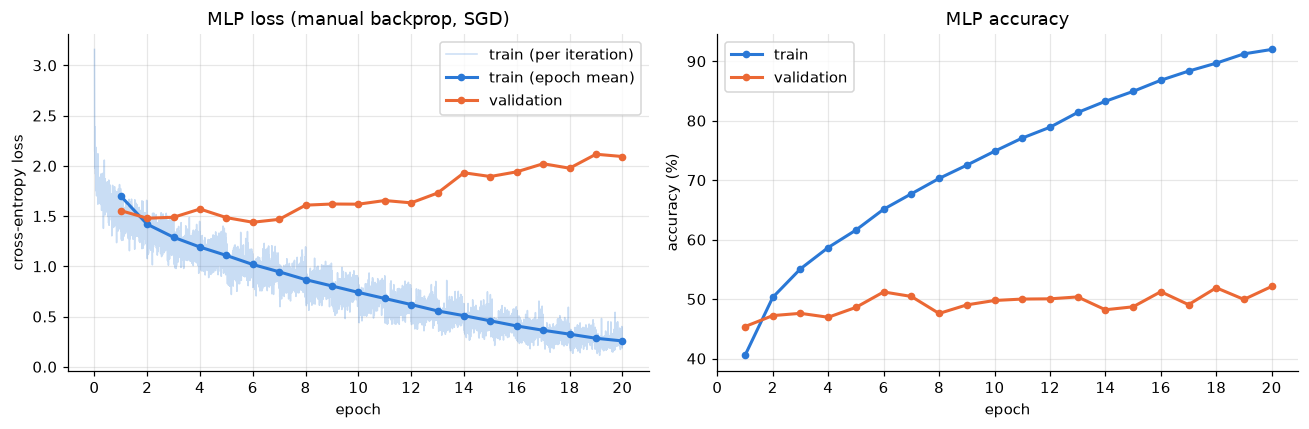

In [9]:
iters_per_epoch = len(train_loader)
epoch_axis = np.arange(1, epochs + 1)
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))

ax_loss.plot(np.arange(1, len(history['iter_loss']) + 1) / iters_per_epoch, history['iter_loss'],
             color=COLORS[0], alpha=0.25, linewidth=1, label='train (per iteration)')
ax_loss.plot(epoch_axis, history['train_loss'], color=COLORS[0], marker='o', markersize=4, label='train (epoch mean)')
ax_loss.plot(epoch_axis, history['val_loss'], color=COLORS[1], marker='o', markersize=4, label='validation')
ax_loss.set(xlabel='epoch', ylabel='cross-entropy loss', title='MLP loss (manual backprop, SGD)')
ax_loss.legend()

ax_acc.plot(epoch_axis, np.array(history['train_acc']) * 100, color=COLORS[0], marker='o', markersize=4, label='train')
ax_acc.plot(epoch_axis, np.array(history['val_acc']) * 100, color=COLORS[1], marker='o', markersize=4, label='validation')
ax_acc.set(xlabel='epoch', ylabel='accuracy (%)', title='MLP accuracy')
ax_acc.legend()
for ax in (ax_loss, ax_acc):
    ax.set_xticks(np.arange(0, epochs + 1, 2))
plt.tight_layout()
plt.show()

**Interpretation.** The MLP reaches **≈52 % validation accuracy** after 20 epochs, against 10 % for random guessing.

**The curves show overfitting.** Training loss falls steadily from 1.70 to 0.26, and training accuracy reaches ≈92 %. Validation loss is lowest at epoch 6 (≈1.44) and then rises to ≈2.1, while validation accuracy stays flat at 48–52 %. With ≈1.7 M parameters and no weight sharing, the MLP memorises the training images instead of learning features that generalise.

**Validation loss rises while validation accuracy holds.** The network becomes over-confident on the images it still gets wrong, and cross-entropy punishes confident mistakes heavily.

**Flattening also discards the 2-D structure of the image.** The same cat shifted by a few pixels becomes a completely different input vector. This motivates the CNNs in the later tasks.

**The per-iteration loss is noisy** because each SGD step uses a gradient estimated from only 128 images.

### 1(d) Per-layer gradient norms in a 10-layer MLP

Ten Linear layers (3072 → 256 × 9 → 10) with the **same** Kaiming initial weights; only the activation differs. One forward/backward pass at initialization on a batch of 512 training images gives $\lVert \partial L/\partial W_l \rVert$ for each layer $l$.

layer       Sigmoid        ReLU
1          1.48e-04    3.27e+00
2          2.03e-04    1.40e+00
3          7.01e-04    1.71e+00
4          2.18e-03    2.14e+00
5          6.45e-03    2.33e+00
6          1.98e-02    2.86e+00
7          5.99e-02    3.03e+00
8          1.90e-01    2.87e+00
9          6.06e-01    3.22e+00
10         1.82e+00    3.25e+00
Sigmoid: layer 1 / layer 10 gradient-norm ratio = 8.1e-05
ReLU: layer 1 / layer 10 gradient-norm ratio = 1.0e+00


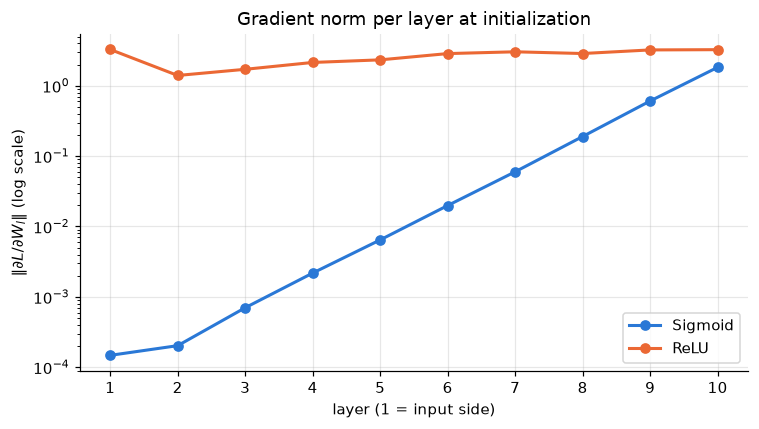

In [10]:
def layer_gradient_norms(activation, x, labels):
    torch.manual_seed(SEED)                                             # identical initial weights for both runs
    deep_mlp = MLP([3072] + [256] * 9 + [10], activation=activation, device=device)
    deep_mlp.loss(x, labels)
    deep_mlp.backward()
    return [layer.dW.norm().item() for layer in deep_mlp.linear_layers()]


images, labels = next(iter(DataLoader(train_dataset, batch_size=512, shuffle=False)))
x_batch, y_batch = images.view(len(images), -1).to(device), labels.to(device)
grad_norms = {'Sigmoid': layer_gradient_norms(Sigmoid, x_batch, y_batch),
              'ReLU': layer_gradient_norms(ReLU, x_batch, y_batch)}

print(f"{'layer':<7}{'Sigmoid':>12}{'ReLU':>12}")
for l, (s, r) in enumerate(zip(grad_norms['Sigmoid'], grad_norms['ReLU']), start=1):
    print(f'{l:<7}{s:>12.2e}{r:>12.2e}')
for name, norms in grad_norms.items():
    print(f'{name}: layer 1 / layer 10 gradient-norm ratio = {norms[0] / norms[-1]:.1e}')

layer_axis = np.arange(1, 11)
plt.figure(figsize=(7, 4))
for color, (name, norms) in zip(COLORS, grad_norms.items()):
    plt.semilogy(layer_axis, norms, color=color, marker='o', markersize=6, label=name)
plt.xticks(layer_axis)
plt.xlabel('layer (1 = input side)')
plt.ylabel(r'$\|\partial L / \partial W_l\|$ (log scale)')
plt.title('Gradient norm per layer at initialization')
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation.**

**Sigmoid: vanishing gradients.** The gradient norm shrinks by about 3× per layer moving back toward the input. Layer 1 receives only about $10^{-4}$ of layer 10's gradient, so the early layers would barely change during training. The cause is that every backward step multiplies by $\sigma'(z) = \sigma(1-\sigma) \le 0.25$. With Kaiming weights the per-layer gain is about $\sqrt{2\,\mathbb{E}[\sigma'^2]} \approx 0.3$, and nine steps give $0.3^9 \approx 2\times10^{-5}$.

**ReLU: the norm stays flat.** The derivative is exactly 1 on active units and 0 on the roughly half that are inactive. The factor 2 in Kaiming's $\mathrm{Var}(W) = 2/D$ compensates for the switched-off half, so the gain is about $\sqrt{2 \cdot \tfrac12} = 1$. All ten layers stay within the same order of magnitude (1.4–3.3).

**Layer 1 sits above the trend in both curves** because its input is the 3072-dimensional image, which has a larger norm than a 256-unit hidden layer.

This is why deep networks use ReLU with Kaiming initialisation, and why very deep networks also need shortcuts (Task 3(b)).